# Week 5 - Data Cleaning and Preparation

**Paññāsāstra University of Cambodia**
**Course:** Data Analysis and Visualization (3 credits)
**Chapter 5 - Data Cleaning and Preparation**

---

## Session topics (from the course outline)

- Handling missing values
- Data transformation
- Dealing with duplicates
- Changing data types

## Course learning outcomes addressed

| CLO | Statement |
|---|---|
| **CLO 2** | Identify suitable tools and techniques for analyzing different types of datasets |
| **CLO 5** | Perform exploratory data analysis (EDA) to summarize and interpret datasets |
| **CLO 7** | Analyze real-world datasets to identify trends, patterns and relationships |

## Reading

| Topic | Source |
|---|---|
| Handling missing data | McKinney §7.1 |
| Data transformation, duplicates, replacing, binning | McKinney §7.2 |
| Extension (nullable) data types | McKinney §7.3 |
| String manipulation and the `.str` accessor | McKinney §7.4 |
| Handling duplicates | Pfaffelhuber §7.7 |

## The stage that takes the longest

Week 1 listed six stages of an analysis and said that stage 3, cleaning, takes the most time.
This is that session.

The material is not difficult. What makes cleaning hard is that almost every step is a
**decision** rather than a calculation, and the decision depends on why the data is the way
it is which pandas cannot tell you. A missing value might mean "not recorded", "not
applicable", or "zero". Those three call for three different actions, and the cell that fills
them all with `0` looks identical in every case.

The habit this session is trying to build: before you fill or drop anything, say out loud
what you think the missing value means.

---

## Setup

All imports for this notebook are defined in the single cell below. Run it first. If any
import fails, return to Notebook 00 and check that the kernel in the top-right corner points
inside your `venv`.

In [19]:
# ---------------------------------------------------------------------------
# All imports for this notebook. Run this cell first.
# ---------------------------------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Reproducibility: every dataset in this notebook is generated from this seed,
# so your numbers will match the ones shown in the lecture exactly.
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

# Consistent, colour-blind-safe plotting defaults for the whole course.
PALETTE = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3", "#937860"]
plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "figure.dpi": 100,
    "axes.grid": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.alpha": 0.3,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "font.size": 10,
})
sns.set_palette(PALETTE)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)

print("Environment ready.")
print(f"  numpy   {np.__version__}")
print(f"  pandas  {pd.__version__}")
print(f"  seaborn {sns.__version__}")
print(f"  seed    {RANDOM_SEED}")

Environment ready.
  numpy   2.5.3
  pandas  3.0.6
  seaborn 0.13.2
  seed    42


In [29]:
#read
nfl_data = pd.read_csv("NFL.csv")
nfl_data


C:\Users\kim\AppData\Local\Temp\ipykernel_16348\1377793370.py:2: DtypeWarning: Columns (51: BlockingPlayer) have mixed types. Specify dtype option on import or set low_memory=False.
  nfl_data = pd.read_csv("NFL.csv")


,Date,GameID,Drive,qtr,down,time,TimeUnder,TimeSecs,PlayTimeDiff,SideofField,yrdln,yrdline100,ydstogo,ydsnet,GoalToGo,...,ExPoint_Prob,TwoPoint_Prob,ExpPts,EPA,airEPA,yacEPA,Home_WP_pre,Away_WP_pre,Home_WP_post,Away_WP_post,Win_Prob,WPA,airWPA,yacWPA,Season
0,2009-09-10,2009091000,1,1,NaN,15:00,15,3600.0,0.0,TEN,30.0,30.0,0,0,0.0,...,0.0,0.0,0.323526,2.014474,NaN,NaN,0.485675,0.514325,0.546433,0.453567,0.485675,0.060758,NaN,NaN,2009.0
1,2009-09-10,2009091000,1,1,1.0,14:53,15,3593.0,7.0,PIT,42.0,58.0,10,5,0.0,...,0.0,0.0,2.338000,0.077907,-1.068169,1.146076,0.546433,0.453567,0.551088,0.448912,0.546433,0.004655,-0.032244,0.036899,2009.0
2,2009-09-10,2009091000,1,1,2.0,14:16,15,3556.0,37.0,PIT,47.0,53.0,5,2,0.0,...,0.0,0.0,2.415907,-1.402760,NaN,NaN,0.551088,0.448912,0.510793,0.489207,0.551088,-0.040295,NaN,NaN,2009.0
3,2009-09-10,2009091000,1,1,3.0,13:35,14,3515.0,41.0,PIT,44.0,56.0,8,2,0.0,...,0.0,0.0,1.013147,-1.712583,3.318841,-5.031425,0.510793,0.489207,0.461217,0.538783,0.510793,-0.049576,0.106663,-0.156239,2009.0
4,2009-09-10,2009091000,1,1,4.0,13:27,14,3507.0,8.0,PIT,44.0,56.0,8,2,0.0,...,0.0,0.0,-0.699436,2.097796,NaN,NaN,0.461217,0.538783,0.558929,0.441071,0.461217,0.097712,NaN,NaN,2009.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
153986,2012-10-28,2012102800,14,3,1.0,14:53,15,1793.0,7.0,GB,30.0,70.0,10,2,0.0,...,0.0,0.0,1.293852,-0.434942,NaN,NaN,0.564509,0.435491,0.549700,0.450300,0.564509,-0.014809,NaN,NaN,2012.0
153987,2012-10-28,2012102800,14,3,2.0,14:28,15,1768.0,25.0,GB,32.0,68.0,8,8,0.0,...,0.0,0.0,0.858910,0.482972,-0.166440,0.649412,0.549700,0.450300,0.564764,0.435236,0.549700,0.015064,-0.005515,0.020579,2012.0
153988,2012-10-28,2012102800,14,3,3.0,13:54,14,1734.0,34.0,GB,38.0,62.0,2,12,0.0,...,0.0,0.0,1.341882,0.684769,NaN,NaN,0.564764,0.435236,0.587682,0.412318,0.564764,0.022919,NaN,NaN,2012.0
153989,2012-10-28,2012102800,14,3,1.0,13:43,14,1723.0,11.0,GB,38.0,62.0,10,12,0.0,...,0.0,0.0,2.026651,-0.084910,NaN,NaN,0.587682,0.412318,0.583974,0.416026,0.587682,-0.003708,NaN,NaN,2012.0


In [21]:
nfl_data.dropna()

,Date,GameID,Drive,qtr,down,time,TimeUnder,TimeSecs,PlayTimeDiff,SideofField,yrdln,yrdline100,ydstogo,ydsnet,GoalToGo,...,ExPoint_Prob,TwoPoint_Prob,ExpPts,EPA,airEPA,yacEPA,Home_WP_pre,Away_WP_pre,Home_WP_post,Away_WP_post,Win_Prob,WPA,airWPA,yacWPA,Season


In [30]:
missing_values = nfl_data.isnull().sum()

In [23]:
columns_with_missing_values = missing_values[missing_values > 0].index.tolist()


In [26]:
columns_with_na_dropped = nfl_data.dropna(axis=1)
columns_with_na_dropped.head()

,Date,GameID,Drive,qtr,TimeUnder,ydstogo,ydsnet,PlayAttempted,Yards.Gained,sp,Touchdown,Safety,Onsidekick,PlayType,PassAttempt,...,RushAttempt,Reception,Fumble,Sack,Challenge.Replay,Accepted.Penalty,Penalty.Yards,HomeTeam,AwayTeam,Timeout_Indicator,posteam_timeouts_pre,HomeTimeouts_Remaining_Pre,AwayTimeouts_Remaining_Pre,HomeTimeouts_Remaining_Post,AwayTimeouts_Remaining_Post
0,2009-09-10,2009091000,1,1,15,0,0,1,39,0,0,0,0,Kickoff,0,...,0,0,0,0,0,0,0,PIT,TEN,0,3,3,3,3,3
1,2009-09-10,2009091000,1,1,15,10,5,1,5,0,0,0,0,Pass,1,...,0,1,0,0,0,0,0,PIT,TEN,0,3,3,3,3,3
2,2009-09-10,2009091000,1,1,15,5,2,1,-3,0,0,0,0,Run,0,...,1,0,0,0,0,0,0,PIT,TEN,0,3,3,3,3,3
3,2009-09-10,2009091000,1,1,14,8,2,1,0,0,0,0,0,Pass,1,...,0,0,0,0,0,0,0,PIT,TEN,0,3,3,3,3,3
4,2009-09-10,2009091000,1,1,14,8,2,1,0,0,0,0,0,Punt,0,...,0,0,0,0,0,0,0,PIT,TEN,0,3,3,3,3,3


In [27]:
subset_nfl_data = nfl_data.loc[:,'EPA':'Season'].head()
subset_nfl_data

,EPA,airEPA,yacEPA,Home_WP_pre,Away_WP_pre,Home_WP_post,Away_WP_post,Win_Prob,WPA,airWPA,yacWPA,Season
0,2.014474,NaN,NaN,0.485675,0.514325,0.546433,0.453567,0.485675,0.060758,NaN,NaN,2009.0
1,0.077907,-1.068169,1.146076,0.546433,0.453567,0.551088,0.448912,0.546433,0.004655,-0.032244,0.036899,2009.0
2,-1.402760,NaN,NaN,0.551088,0.448912,0.510793,0.489207,0.551088,-0.040295,NaN,NaN,2009.0
3,-1.712583,3.318841,-5.031425,0.510793,0.489207,0.461217,0.538783,0.510793,-0.049576,0.106663,-0.156239,2009.0
4,2.097796,NaN,NaN,0.461217,0.538783,0.558929,0.441071,0.461217,0.097712,NaN,NaN,2009.0


In [28]:
subset_nfl_data.fillna(0)

,EPA,airEPA,yacEPA,Home_WP_pre,Away_WP_pre,Home_WP_post,Away_WP_post,Win_Prob,WPA,airWPA,yacWPA,Season
0,2.014474,0.000000,0.000000,0.485675,0.514325,0.546433,0.453567,0.485675,0.060758,0.000000,0.000000,2009.0
1,0.077907,-1.068169,1.146076,0.546433,0.453567,0.551088,0.448912,0.546433,0.004655,-0.032244,0.036899,2009.0
2,-1.402760,0.000000,0.000000,0.551088,0.448912,0.510793,0.489207,0.551088,-0.040295,0.000000,0.000000,2009.0
3,-1.712583,3.318841,-5.031425,0.510793,0.489207,0.461217,0.538783,0.510793,-0.049576,0.106663,-0.156239,2009.0
4,2.097796,0.000000,0.000000,0.461217,0.538783,0.558929,0.441071,0.461217,0.097712,0.000000,0.000000,2009.0


In [ ]:
#Bfill=beforefill
subset_nfl_data = subset_nfl_data.bfill(axis=0).fillna(0)
subset_nfl_data


,EPA,airEPA,yacEPA,Home_WP_pre,Away_WP_pre,Home_WP_post,Away_WP_post,Win_Prob,WPA,airWPA,yacWPA,Season
0,2.014474,-1.068169,1.146076,0.485675,0.514325,0.546433,0.453567,0.485675,0.060758,-0.032244,0.036899,2009.0
1,0.077907,-1.068169,1.146076,0.546433,0.453567,0.551088,0.448912,0.546433,0.004655,-0.032244,0.036899,2009.0
2,-1.402760,3.318841,-5.031425,0.551088,0.448912,0.510793,0.489207,0.551088,-0.040295,0.106663,-0.156239,2009.0
3,-1.712583,3.318841,-5.031425,0.510793,0.489207,0.461217,0.538783,0.510793,-0.049576,0.106663,-0.156239,2009.0
4,2.097796,0.000000,0.000000,0.461217,0.538783,0.558929,0.441071,0.461217,0.097712,0.000000,0.000000,2009.0


In [36]:
landslide_data = pd.read_csv("catalogs.csv")

In [40]:
print(landslide_data.head())

   id     date   time continent_code   country_name country_code state/province  population         city/town  \
0  34   3/2/07  Night            NaN  United States           US       Virginia       16000       Cherry Hill   
1  42  3/22/07    NaN            NaN  United States           US           Ohio       17288  New Philadelphia   
2  56   4/6/07    NaN            NaN  United States           US   Pennsylvania       15930       Wilkinsburg   
3  59  4/14/07    NaN            NaN         Canada           CA         Quebec       42786       Châteauguay   
4  61  4/15/07    NaN            NaN  United States           US       Kentucky        6903         Pikeville   

   distance location_description  latitude  longitude                                geolocation hazard_type  \
0   3.40765              Unknown   38.6009   -77.2682  (38.600900000000003, -77.268199999999993)   Landslide   
1   3.33522                  NaN   40.5175   -81.4305  (40.517499999999998, -81.430499999999995) 

In [44]:
print(landslide_data.head())

   id     date   time continent_code   country_name country_code state/province  population         city/town  \
0  34   3/2/07  Night            NaN  United States           US       Virginia       16000       Cherry Hill   
1  42  3/22/07    NaN            NaN  United States           US           Ohio       17288  New Philadelphia   
2  56   4/6/07    NaN            NaN  United States           US   Pennsylvania       15930       Wilkinsburg   
3  59  4/14/07    NaN            NaN         Canada           CA         Quebec       42786       Châteauguay   
4  61  4/15/07    NaN            NaN  United States           US       Kentucky        6903         Pikeville   

   distance location_description  latitude  longitude                                geolocation hazard_type  \
0   3.40765              Unknown   38.6009   -77.2682  (38.600900000000003, -77.268199999999993)   Landslide   
1   3.33522                  NaN   40.5175   -81.4305  (40.517499999999998, -81.430499999999995) 

NameError: name 'landslides' is not defined

NameError: name 'landslide' is not defined

NameError: name 'landslide' is not defined

NameError: name 'landslide' is not defined

NameError: name 'landslide' is not defined

In [56]:
import fuzzywuzzy
from fuzzywuzzy import process
import charset_normalizer
professors =pd.read_csv('pakistan_intellectual_capital.csv')

In [58]:
professors .head()


,Unnamed: 0,S#,Teacher Name,University Currently Teaching,Department,Province University Located,Designation,Terminal Degree,Graduated from,Country,Year,Area of Specialization/Research Interests,Other Information
0,2,3,Dr. Abdul Basit,University of Balochistan,Computer Science & IT,Balochistan,Assistant Professor,PhD,Asian Institute of Technology,Thailand,NaN,Software Engineering & DBMS,NaN
1,4,5,Dr. Waheed Noor,University of Balochistan,Computer Science & IT,Balochistan,Assistant Professor,PhD,Asian Institute of Technology,Thailand,NaN,DBMS,NaN
2,5,6,Dr. Junaid Baber,University of Balochistan,Computer Science & IT,Balochistan,Assistant Professor,PhD,Asian Institute of Technology,Thailand,NaN,"Information processing, Multimedia mining",NaN
3,6,7,Dr. Maheen Bakhtyar,University of Balochistan,Computer Science & IT,Balochistan,Assistant Professor,PhD,Asian Institute of Technology,Thailand,NaN,"NLP, Information Retrieval, Question Answering...",NaN
4,24,25,Samina Azim,Sardar Bahadur Khan Women's University,Computer Science,Balochistan,Lecturer,BS,Balochistan University of Information Technolo...,Pakistan,2005.0,VLSI Electronics DLD Database,NaN


In [67]:
countries  = professors['Country'].unique()
countries.searchsorted(countries)
#countries=sorted(countries)
print(countries)

<StringArray>
[          'Thailand',           'Pakistan',            'germany',            'Austria',          'Australia',
                 'UK',              'China',             'France',              'USofA',         'SouthKorea',
           'Malaysia',             'Sweden',              'Italy',             'Canada',             'Norway',
            'Ireland',        'New Zealand',             'Urbana',           'Portugal', 'Russian Federation',
                'USA',            'Finland',               ' USA',         'Netherland',           ' Germany',
            ' Sweden',       ' New Zealand',             'Greece',             'Turkey',        'South Korea',
              'Macau',          'Singapore',              'Spain',              'Japan',           'HongKong',
       'Saudi Arabia',          'Mauritius',           'Scotland']
Length: 38, dtype: str


In [71]:
professors['Country'] = professors['Country'].str.strip()
professors['Country'] = professors['Country'].str.lower()
countries


<StringArray>
[          'Thailand',           'Pakistan',            'germany',            'Austria',          'Australia',
                 'UK',              'China',             'France',              'USofA',         'SouthKorea',
           'Malaysia',             'Sweden',              'Italy',             'Canada',             'Norway',
            'Ireland',        'New Zealand',             'Urbana',           'Portugal', 'Russian Federation',
                'USA',            'Finland',               ' USA',         'Netherland',           ' Germany',
            ' Sweden',       ' New Zealand',             'Greece',             'Turkey',        'South Korea',
              'Macau',          'Singapore',              'Spain',              'Japan',           'HongKong',
       'Saudi Arabia',          'Mauritius',           'Scotland']
Length: 38, dtype: str

In [73]:
countries  = professors['Country'].unique()
countries.searchsorted(countries)
print(countries)

<StringArray>
[          'thailand',           'pakistan',            'germany',            'austria',          'australia',
                 'uk',              'china',             'france',              'usofa',         'southkorea',
           'malaysia',             'sweden',              'italy',             'canada',             'norway',
            'ireland',        'new zealand',             'urbana',           'portugal', 'russian federation',
                'usa',            'finland',         'netherland',             'greece',             'turkey',
        'south korea',              'macau',          'singapore',              'spain',              'japan',
           'hongkong',       'saudi arabia',          'mauritius',           'scotland']
Length: 34, dtype: str


In [75]:
matches = fuzzywuzzy.process.extract("South Korea", countries, limit=10,scorer=fuzzywuzzy.fuzz.token_sort_ratio)
matches

[('south korea', 100),
 ('southkorea', 48),
 ('saudi arabia', 43),
 ('norway', 35),
 ('ireland', 33),
 ('portugal', 32),
 ('singapore', 30),
 ('netherland', 29),
 ('usofa', 25),
 ('macau', 25)]

In [88]:
# function to replace rows in the provided column of the provided dataframe
# that match the provided string above the provided ratio with the provided string
def replace_matches_in_column(df, column, string_to_match, min_ratio = 45):
    # get a list of unique strings
    strings = df[column].unique()
    
    # get the top 10 closest matches to our input string
    matches = fuzzywuzzy.process.extract(string_to_match, strings, 
                                         limit=10, scorer=fuzzywuzzy.fuzz.token_sort_ratio)

    # only get matches with a ratio > 90
    close_matches = [matches[0] for matches in matches if matches[1] >= min_ratio]

    # get the rows of all the close matches in our dataframe
    rows_with_matches = df[column].isin(close_matches)

    # replace all rows with close matches with the input matches 
    df.loc[rows_with_matches, column] = string_to_match
    
    # let us know the function's done
    print("All done!")

In [89]:
replace_matches_in_column(df=professors, column="Country", string_to_match="south_korea")

All done!


In [90]:
countries  = professors['Country'].unique()
countries.searchsorted(countries)
print(countries)

<StringArray>
[          'thailand',           'pakistan',            'germany',            'austria',          'australia',
                 'uk',              'china',             'france',              'usofa',        'south_korea',
           'malaysia',             'sweden',              'italy',             'canada',             'norway',
            'ireland',        'new zealand',             'urbana',           'portugal', 'russian federation',
                'usa',            'finland',         'netherland',             'greece',             'turkey',
              'macau',          'singapore',              'spain',              'japan',           'hongkong',
       'saudi arabia',          'mauritius',           'scotland']
Length: 33, dtype: str


---

# Part 1 - Theory and concepts

## 1.1 What "missing" is, mechanically

pandas has more than one missing marker, and which one appears depends on the column's dtype.

| Marker | Appears in | Notes |
|---|---|---|
| `np.nan` | float columns | A float value defined by IEEE-754. `nan != nan` |
| `None` | object columns | Python's null; pandas usually converts it to `NaN` |
| `NaT` | datetime and timedelta columns | "Not a Time" |
| `pd.NA` | nullable extension dtypes (`Int64`, `boolean`, `string`) | The newer, dtype-independent marker |

Test for all of them with `pd.isna()`, which handles every case. Do **not** use `np.isnan()`,
which raises on `NaT` and on strings, and do not use `== np.nan`, which is always `False`
because `nan` is not equal to itself.

## 1.2 `NaN` is a float, and that changes your dtypes

This catches everyone once.

```python
s = pd.Series([1, 2, 3])        # dtype int64
s[0] = np.nan                   # dtype becomes float64
```

An integer column cannot hold `NaN`, because `NaN` is a floating-point value. The moment a
missing value appears, pandas promotes the whole column to `float64`. Your student IDs become
`1001.0`, and printing them looks wrong.

Two ways out:

- **`Int64`** (capital I) is pandas' *nullable* integer type. It holds `pd.NA` without
  promoting. Convert with `series.astype("Int64")`.
- **Fill first, convert afterwards**: `series.fillna(0).astype(int)`.

The same applies to booleans: a `bool` column with a missing value becomes `object`, and the
nullable equivalent is `"boolean"`.

## 1.3 Finding missing values

```python
df.isna()                 # a boolean frame the same shape
df.isna().sum()           # count per column
df.isna().sum().sum()     # total
df.isna().mean() * 100    # percentage per column
df[df["col"].isna()]      # the rows where one column is missing
```

`df.info()` gives the non-null count per column, which is the same information read the other
way round.

## 1.4 The decision: why is it missing?

This is the part that matters, and it is not a pandas question.

| Reason | Example | Reasonable action |
|---|---|---|
| **Not recorded** | The sensor was offline | Leave as `NaN`, or fill from neighbouring values |
| **Not applicable** | "Spouse's name" for an unmarried person | Leave as `NaN`; it is not an error |
| **Means zero** | No sales that day, exported as blank | Fill with `0` |
| **Lost in transfer** | An encoding failure | Go back to the source if you can |
| **Deliberately withheld** | The respondent declined | Leave as `NaN`, and report how many |

Filling a "not recorded" value with `0` invents data. Leaving a "means zero" value as `NaN`
throws data away. Both are wrong, and they are wrong in opposite directions, so there is no
safe default.

**The rule for this course:** whenever you fill or drop, write a comment saying why. If you
cannot write the comment, you do not yet know enough to make the change.

One more consideration. Dropping rows with missing values is only safe when the missingness
is unrelated to what you are studying. If students with low attendance are the ones who did
not submit the survey, dropping them biases every conclusion towards the diligent. The
statistical name for the safe case is *missing completely at random*; the point to remember
is that it is an assumption, not a fact.

## 1.5 Dropping

```python
df.dropna()                                  # any row with any missing value
df.dropna(how="all")                         # only rows that are entirely missing
df.dropna(subset=["gpa"])                    # only where these columns are missing
df.dropna(thresh=3)                          # keep rows with at least 3 non-null values
df.dropna(axis=1)                            # drop COLUMNS instead of rows
```

`df.dropna()` with no arguments is the most destructive call in pandas: one missing value
anywhere in a row removes the whole row. On a wide table that can delete most of your data
while looking like a tidy-up. Always check `len()` before and after.

## 1.6 Filling

```python
df["col"].fillna(0)                          # a constant
df["col"].fillna(df["col"].median())         # a summary statistic
df["col"].ffill()                            # carry the previous value forward
df["col"].bfill()                            # carry the next value backward
df.groupby("faculty")["gpa"].transform("median")   # a group-specific statistic
```

Filling with the **median** is usually safer than the mean, because the median is not dragged
by the outliers that often accompany messy data.

Filling **within a group** is better still when the groups differ: replacing a missing
Engineering GPA with the Engineering median says more than replacing it with the overall
median. `groupby(...).transform(...)` returns a result aligned to the original rows, which is
exactly what `fillna` needs.

`ffill` and `bfill` are for **ordered** data — time series, mostly — where the previous
observation is a reasonable estimate of the current one. On unordered rows they propagate
whatever happened to be above, which is meaningless.

## 1.7 Duplicates

```python
df.duplicated()                      # True for the 2nd and later copies
df.duplicated(keep=False)            # True for EVERY row in a duplicated group
df.duplicated(subset=["student_id"]) # duplicates by key, ignoring other columns
df.drop_duplicates()
df.drop_duplicates(subset=["student_id"], keep="last")
```

The `keep` parameter decides which copy is considered original: `"first"` (the default),
`"last"`, or `False` meaning none of them. `keep=False` in `duplicated()` is how you *find*
all the offending rows to look at them; `keep="first"` in `drop_duplicates()` is how you
remove them.

A genuine duplicate row and a legitimately repeated measurement look identical to pandas.
Deduplicate on the column that is supposed to be unique — the key — rather than on the whole
row, unless you are sure whole-row repetition is impossible.

## 1.8 Changing types

```python
series.astype(int)                            # strict: raises on anything unconvertible
pd.to_numeric(series, errors="coerce")        # lenient: unconvertible becomes NaN
pd.to_datetime(series, errors="coerce")       # same, for dates
series.astype("category")                     # for low-cardinality text
```

`astype` is strict and `to_numeric`/`to_datetime` with `errors="coerce"` are lenient. Use the
lenient form when reading unknown data, then count how many values became `NaN` — that count
tells you how bad the column is.

`"category"` stores each distinct value once and replaces the column with integer codes. On a
column of a few repeated strings it saves a great deal of memory and speeds up grouping.

## 1.9 Cleaning strings

The `.str` accessor applies a string method to every element:

```python
df["name"].str.strip()
df["name"].str.lower()
df["name"].str.replace(",", "", regex=False)
df["faculty"].str.contains("Eng", na=False)
df["code"].str.zfill(4)                       # restore leading zeros
```

Whitespace is the most common invisible problem in text data: `"Engineering"` and
`"Engineering "` are different values, group separately, and look identical when printed.
`.str.strip()` on every text column is a defensible default first step.

Pass `na=False` to `.str.contains()`, or missing values produce `NaN` in the mask and the
mask cannot then be used for indexing.

## 1.10 Views, copies, and chained assignment

Week 3 established that a NumPy slice is a view. The same question arises in pandas, and it
produces the most-searched warning in the library.

```python
df[df["gpa"] < 2.0]["status"] = "probation"       # DOES NOT WORK
```

This is **chained assignment**: two operations, `df[mask]` then `["status"] = ...`. The first
produces a new object, and the assignment modifies that temporary object, which is then
discarded. The original `df` is unchanged.

What pandas does about it depends on the version:

| Version | Behaviour |
|---|---|
| pandas 1.x–2.x | Raises `SettingWithCopyWarning`. The write *may* reach the original, depending on memory layout — which is worse than failing |
| pandas 3.0+ | Copy-on-Write is always on. Raises `ChainedAssignmentError` and the write **never** reaches the original |

The fix is the same in every version: **do it in one operation with `.loc`.**

```python
df.loc[df["gpa"] < 2.0, "status"] = "probation"   # works
```

One indexing operation, both axes named, no intermediate object. This is why Week 4 insisted
on `.loc` over the convenience form: it is not style, it is the difference between an
assignment that happens and one that does not.

---

---

# Part 2 - Code example

The dataset below is generated with deliberate defects: missing values of three different
kinds, duplicate rows, inconsistent text, and a numeric column stored as text. Everything in
Part 1 is then applied to it.

## 2.1 A deliberately messy dataset

In [91]:
def generate_messy_enrolments(n: int = 150, seed: int = RANDOM_SEED) -> pd.DataFrame:
    """Build a reproducible enrolment frame containing realistic defects.

    Defects introduced, all of which occur in real administrative exports:
      - missing GPA (not recorded) and missing scholarship_usd (means zero)
      - inconsistent whitespace and capitalisation in `faculty`
      - `credits` stored as text, with one unparseable value
      - six duplicated rows
      - two rows that are entirely empty apart from the identifier

    Parameters
    ----------
    n : int
        Number of base records before duplicates are added.
    seed : int
        Seed for reproducibility.

    Returns
    -------
    pandas.DataFrame
    """
    generator = np.random.default_rng(seed)

    faculties = ["Engineering", "Business", "Science", "Arts"]
    faculty = generator.choice(faculties, size=n, p=[0.35, 0.30, 0.20, 0.15])
    ability = generator.normal(0, 1, size=n)

    frame = pd.DataFrame({
        "student_id": [f"S{2026000 + i}" for i in range(n)],
        "faculty": faculty,
        "credits": generator.choice([12, 15, 18], size=n, p=[0.25, 0.50, 0.25]),
        "gpa": np.clip(2.6 + ability * 0.5, 0, 4).round(2),
        "attendance_pct": np.clip(78 + ability * 9 + generator.normal(0, 5, n),
                                  0, 100).round(1),
        "scholarship_usd": np.where(
            generator.random(n) < 0.25,
            (generator.integers(200, 1200, size=n) // 50 * 50).astype(float),
            0.0,
        ),
    })

    # Missing GPA: not recorded for 12% of students.
    frame.loc[generator.random(n) < 0.12, "gpa"] = np.nan

    # Missing scholarship: exported as blank where the amount was zero.
    frame.loc[frame["scholarship_usd"] == 0, "scholarship_usd"] = np.nan

    # Missing attendance for a few students.
    frame.loc[generator.random(n) < 0.05, "attendance_pct"] = np.nan

    # Inconsistent text: stray whitespace and capitalisation.
    messy_text = generator.random(n)
    frame.loc[messy_text < 0.10, "faculty"] = frame.loc[messy_text < 0.10, "faculty"] + " "
    frame.loc[messy_text > 0.92, "faculty"] = frame.loc[messy_text > 0.92, "faculty"].str.upper()

    # credits stored as text, with one unparseable entry.
    frame["credits"] = frame["credits"].astype(str)
    frame.loc[7, "credits"] = "not recorded"

    # Two rows that are empty apart from the identifier.
    for position in [30, 90]:
        frame.loc[position, ["faculty", "credits", "gpa",
                             "attendance_pct", "scholarship_usd"]] = np.nan

    # Six duplicated rows, appended at the end.
    duplicates = frame.iloc[[3, 11, 25, 44, 60, 77]].copy()
    frame = pd.concat([frame, duplicates], ignore_index=True)

    return frame


messy = generate_messy_enrolments()

print("shape:", messy.shape)
print()
print(messy.head(8))

shape: (156, 6)

  student_id      faculty       credits   gpa  attendance_pct  scholarship_usd
0   S2026000      Science            15  3.13            89.2              NaN
1   S2026001     Business            15   NaN            81.2              NaN
2   S2026002         Arts            12  2.52            83.2              NaN
3   S2026003      Science            15  2.08            67.0              NaN
4   S2026004  Engineering            15  1.76            55.5           1100.0
5   S2026005         Arts            15   NaN            79.0            350.0
6   S2026006      Science            15  2.57            75.9              NaN
7   S2026007      Science  not recorded  3.48            99.5              NaN


In [92]:
# The first inspection from Week 4, on a frame that needs it.
messy.info()

print("\nMissing values per column:")
missing = pd.DataFrame({
    "n_missing": messy.isna().sum(),
    "pct": (messy.isna().mean() * 100).round(1),
})
print(missing[missing["n_missing"] > 0])

print(f"\nTotal missing values: {int(messy.isna().sum().sum())}")
print(f"Rows with at least one missing value: {int(messy.isna().any(axis=1).sum())} "
      f"of {len(messy)}")

<class 'pandas.DataFrame'>
RangeIndex: 156 entries, 0 to 155
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   student_id       156 non-null    str    
 1   faculty          154 non-null    str    
 2   credits          154 non-null    str    
 3   gpa              138 non-null    float64
 4   attendance_pct   149 non-null    float64
 5   scholarship_usd  41 non-null     float64
dtypes: float64(3), str(3)
memory usage: 7.4 KB

Missing values per column:
                 n_missing   pct
faculty                  2   1.3
credits                  2   1.3
gpa                     18  11.5
attendance_pct           7   4.5
scholarship_usd        115  73.7

Total missing values: 144
Rows with at least one missing value: 121 of 156


## 2.2 `NaN` is a float

Before cleaning anything, a demonstration of why the `credits` column will need care.

In [93]:
# An integer Series that acquires a missing value is promoted to float.
counts = pd.Series([10, 20, 30, 40])
print("Original :", counts.dtype, counts.tolist())

with_missing = counts.copy()
with_missing[1] = np.nan
print("With NaN :", with_missing.dtype, with_missing.tolist())

print("\nThe values are now 10.0, nan, 30.0, 40.0. An int64 column cannot hold")
print("NaN, because NaN is a floating-point value, so pandas promotes the")
print("whole column. Identifiers printed as 1001.0 are this, every time.")

# The nullable integer type holds pd.NA without promoting.
nullable = pd.Series([10, 20, 30, 40], dtype="Int64")
nullable[1] = pd.NA
print("\nAs Int64  :", nullable.dtype, nullable.tolist())
print("Note the capital I. 'int64' is the NumPy type; 'Int64' is the pandas")
print("nullable type, which has a missing marker of its own.")

# pd.isna handles every marker; np.isnan and == do not.
print("\npd.isna(np.nan), pd.isna(pd.NaT), pd.isna(None), pd.isna(pd.NA):",
      pd.isna(np.nan), pd.isna(pd.NaT), pd.isna(None), pd.isna(pd.NA))
print("np.nan == np.nan  ->", np.nan == np.nan, " (never compare with ==)")

Original : int64 [10, 20, 30, 40]
With NaN : float64 [10.0, nan, 30.0, 40.0]

The values are now 10.0, nan, 30.0, 40.0. An int64 column cannot hold
NaN, because NaN is a floating-point value, so pandas promotes the
whole column. Identifiers printed as 1001.0 are this, every time.

As Int64  : Int64 [10, <NA>, 30, 40]
Note the capital I. 'int64' is the NumPy type; 'Int64' is the pandas
nullable type, which has a missing marker of its own.

pd.isna(np.nan), pd.isna(pd.NaT), pd.isna(None), pd.isna(pd.NA): True True True True
np.nan == np.nan  -> False  (never compare with ==)


## 2.3 Dropping

Four variants of `dropna`, and the damage each does.

In [97]:
print(f"{'call':<42}{'rows kept':>11}{'lost':>8}")
print("-" * 61)
original = len(messy)
variants = {
    "no cleaning": messy,
    "dropna()": messy.dropna(),
    "dropna(how='all')": messy.dropna(how="all"),
    "dropna(subset=['gpa'])": messy.dropna(subset=["gpa"]),
    "dropna(thresh=4)": messy.dropna(thresh=4),
}
for label, frame in variants.items():
    print(f"{label:<42}{len(frame):>11}{original - len(frame):>8}")

print(f"\ndropna() with no arguments removes "
      f"{original - len(messy.dropna())} of {original} rows — "
      f"{(original - len(messy.dropna())) / original * 100:.0f}% of the data.")
print("\nOne missing value anywhere in a row removes the whole row. On a wide")
print("table this deletes most of the data while looking like a tidy-up.")
print("Always compare len() before and after.")

call                                        rows kept    lost
-------------------------------------------------------------
no cleaning                                       156       0
dropna()                                           35     121
dropna(how='all')                                 156       0
dropna(subset=['gpa'])                            138      18
dropna(thresh=4)                                  154       2

dropna() with no arguments removes 121 of 156 rows — 78% of the data.

One missing value anywhere in a row removes the whole row. On a wide
table this deletes most of the data while looking like a tidy-up.
Always compare len() before and after.


In [98]:
# The two rows that are genuinely empty are the ones worth dropping outright.
key_columns = ["faculty", "credits", "gpa", "attendance_pct", "scholarship_usd"]
empty_rows = messy[messy[key_columns].isna().all(axis=1)]

print(f"Rows empty apart from the identifier: {len(empty_rows)}")
print(empty_rows)

print("\nThese carry no information, so dropping them loses nothing.")
print("That is a different judgement from dropping a row because ONE field")
print("is missing.")

Rows empty apart from the identifier: 2
   student_id faculty credits  gpa  attendance_pct  scholarship_usd
30   S2026030     NaN     NaN  NaN             NaN              NaN
90   S2026090     NaN     NaN  NaN             NaN              NaN

These carry no information, so dropping them loses nothing.
That is a different judgement from dropping a row because ONE field
is missing.


## 2.4 Filling

The choice of fill value is a claim about what the missing value meant.

In [99]:
gpa = messy["gpa"]
print(f"gpa: {gpa.isna().sum()} missing of {len(gpa)}")
print(f"  observed mean   {gpa.mean():.3f}")
print(f"  observed median {gpa.median():.3f}")

comparison = pd.DataFrame({
    "constant_0": gpa.fillna(0),
    "mean": gpa.fillna(gpa.mean()),
    "median": gpa.fillna(gpa.median()),
})
print("\nWhat each choice does to the column statistics:")
print(comparison.agg(["mean", "std", "min"]).round(3))

print("\nFilling with 0 moves the mean a long way and invents 18 students with")
print("a GPA of zero. It is the wrong answer here: a missing GPA means")
print("'not recorded', not 'scored nothing'.")

gpa: 18 missing of 156
  observed mean   2.580
  observed median 2.525

What each choice does to the column statistics:
      constant_0   mean  median
mean       2.283  2.580   2.574
std        0.947  0.462   0.462
min        0.000  1.320   1.320

Filling with 0 moves the mean a long way and invents 18 students with
a GPA of zero. It is the wrong answer here: a missing GPA means
'not recorded', not 'scored nothing'.


In [100]:
# Filling within a group says more than filling from the whole column.
clean_faculty = messy["faculty"].str.strip().str.title()

group_median = messy.assign(faculty=clean_faculty).groupby("faculty")["gpa"].transform("median")
overall_median = messy["gpa"].median()

filled = pd.DataFrame({
    "faculty": clean_faculty,
    "gpa": messy["gpa"],
    "by_overall": messy["gpa"].fillna(overall_median),
    "by_faculty": messy["gpa"].fillna(group_median),
})

print("Faculty medians:")
print(filled.groupby("faculty")["gpa"].median().round(3))

print(f"\nOverall median: {overall_median:.3f}")

print("\nRows where the two approaches disagree, first six:")
disagree = filled[filled["gpa"].isna()].head(6)
print(disagree[["faculty", "by_overall", "by_faculty"]].round(3).to_string())

print("\ntransform('median') returns a value per ROW, aligned to the original")
print("index, which is what fillna needs. agg('median') would return one value")
print("per group and would not align.")

Faculty medians:
faculty
Arts           2.480
Business       2.565
Engineering    2.520
Science        2.545
Name: gpa, dtype: float64

Overall median: 2.525

Rows where the two approaches disagree, first six:
        faculty  by_overall  by_faculty
1      Business       2.525       2.565
5          Arts       2.525       2.480
25  Engineering       2.525       2.520
29      Science       2.525       2.545
30          NaN       2.525         NaN
32  Engineering       2.525       2.520

transform('median') returns a value per ROW, aligned to the original
index, which is what fillna needs. agg('median') would return one value
per group and would not align.


In [101]:
# ffill and bfill are for ORDERED data only.
readings = pd.Series([20.1, np.nan, np.nan, 21.4, np.nan, 22.0],
                     index=pd.date_range("2026-03-01", periods=6, freq="D"))

print("Daily sensor readings with gaps:")
print(readings)

print("\nffill (carry the last observation forward):")
print(readings.ffill())

print("\nbfill (carry the next observation backward):")
print(readings.bfill())

print("\nThese make sense here because the rows are in time order and a")
print("temperature does not jump. On unordered rows they simply propagate")
print("whatever happened to be above, which means nothing.")

Daily sensor readings with gaps:
2026-03-01    20.1
2026-03-02     NaN
2026-03-03     NaN
2026-03-04    21.4
2026-03-05     NaN
2026-03-06    22.0
Freq: D, dtype: float64

ffill (carry the last observation forward):
2026-03-01    20.1
2026-03-02    20.1
2026-03-03    20.1
2026-03-04    21.4
2026-03-05    21.4
2026-03-06    22.0
Freq: D, dtype: float64

bfill (carry the next observation backward):
2026-03-01    20.1
2026-03-02    21.4
2026-03-03    21.4
2026-03-04    21.4
2026-03-05    22.0
2026-03-06    22.0
Freq: D, dtype: float64

These make sense here because the rows are in time order and a
temperature does not jump. On unordered rows they simply propagate
whatever happened to be above, which means nothing.


## 2.5 Duplicates

In [102]:
print(f"Fully duplicated rows        : {int(messy.duplicated().sum())}")
print(f"Duplicated student_id values : {int(messy.duplicated(subset=['student_id']).sum())}")

print("\nkeep='first' (the default) marks the 2nd and later copies:")
print(messy[messy.duplicated(subset=["student_id"])][["student_id", "faculty", "gpa"]])

print("\nkeep=False marks EVERY row in a duplicated group, which is what you")
print("want when inspecting them:")
all_copies = messy[messy.duplicated(subset=["student_id"], keep=False)]
print(all_copies[["student_id", "faculty", "gpa"]].sort_values("student_id"))

deduplicated = messy.drop_duplicates(subset=["student_id"], keep="first")
print(f"\nAfter drop_duplicates: {len(messy)} -> {len(deduplicated)} rows")

Fully duplicated rows        : 6
Duplicated student_id values : 6

keep='first' (the default) marks the 2nd and later copies:
    student_id      faculty   gpa
150   S2026003      Science  2.08
151   S2026011         Arts  2.01
152   S2026025  Engineering   NaN
153   S2026044      Science  2.41
154   S2026060      Science  2.16
155   S2026077      Science   NaN

keep=False marks EVERY row in a duplicated group, which is what you
want when inspecting them:
    student_id      faculty   gpa
3     S2026003      Science  2.08
150   S2026003      Science  2.08
11    S2026011         Arts  2.01
151   S2026011         Arts  2.01
25    S2026025  Engineering   NaN
152   S2026025  Engineering   NaN
44    S2026044      Science  2.41
153   S2026044      Science  2.41
60    S2026060      Science  2.16
154   S2026060      Science  2.16
77    S2026077      Science   NaN
155   S2026077      Science   NaN

After drop_duplicates: 156 -> 150 rows


## 2.6 Converting types

In [103]:
print("credits dtype:", messy["credits"].dtype)
print("distinct values:", sorted(messy["credits"].dropna().unique()))

# astype is strict: one bad value and the whole call fails.
try:
    messy["credits"].astype(int)
except ValueError as exc:
    print(f"\nastype(int) raises:\n  ValueError: {str(exc)[:80]}...")

# to_numeric with errors='coerce' converts what it can and marks the rest.
credits_numeric = pd.to_numeric(messy["credits"], errors="coerce")
print(f"\nto_numeric(errors='coerce'): dtype {credits_numeric.dtype}")
print(f"  values that became NaN: {int(credits_numeric.isna().sum() - messy['credits'].isna().sum())}")
print(f"  total missing now     : {int(credits_numeric.isna().sum())}")

print("\nThe count of newly-created NaN is a measure of how bad the column is.")
print("Check it rather than assuming the conversion was clean.")

# Nullable Int64 keeps the values as integers despite the missing entries.
credits_nullable = credits_numeric.astype("Int64")
print(f"\nAs Int64: {credits_nullable.dtype}")
print(credits_nullable.head(9).tolist())

credits dtype: str
distinct values: ['12', '15', '18', 'not recorded']

astype(int) raises:
  ValueError: invalid literal for int() with base 10: 'not recorded'...

to_numeric(errors='coerce'): dtype float64
  values that became NaN: 1
  total missing now     : 3

The count of newly-created NaN is a measure of how bad the column is.
Check it rather than assuming the conversion was clean.

As Int64: Int64
[15, 15, 12, 15, 15, 15, 15, <NA>, 15]


In [104]:
# 'category' for low-cardinality text: less memory, faster grouping.
faculty_clean = messy["faculty"].str.strip().str.title()

as_object = faculty_clean.memory_usage(deep=True)
as_category = faculty_clean.astype("category").memory_usage(deep=True)

print(f"faculty as text     : {as_object:>8,} bytes")
print(f"faculty as category : {as_category:>8,} bytes")
print(f"reduction           : {(1 - as_category / as_object) * 100:.0f}%")
print("\nThe category type stores each distinct value once and replaces the")
print("column with integer codes. Worth doing on any text column with few")
print("distinct values and many rows.")

faculty as text     :    9,026 bytes
faculty as category :      514 bytes
reduction           : 94%

The category type stores each distinct value once and replaces the
column with integer codes. Worth doing on any text column with few
distinct values and many rows.


## 2.7 Cleaning text

Whitespace is the most common invisible defect in text data.

In [105]:
print("Distinct faculty values BEFORE cleaning:")
for value in sorted(messy["faculty"].dropna().unique()):
    print(f"  {value!r}")

print(f"\n{messy['faculty'].nunique()} distinct values for what should be 4 faculties.")
print("Note that 'Engineering' and 'Engineering ' print almost identically")
print("but group separately.")

cleaned_faculty = messy["faculty"].str.strip().str.title()
print("\nAfter .str.strip().str.title():")
for value in sorted(cleaned_faculty.dropna().unique()):
    print(f"  {value!r}")
print(f"\n{cleaned_faculty.nunique()} distinct values.")

Distinct faculty values BEFORE cleaning:
  'ARTS'
  'Arts'
  'BUSINESS'
  'Business'
  'Business '
  'ENGINEERING'
  'Engineering'
  'Engineering '
  'SCIENCE'
  'Science'
  'Science '

11 distinct values for what should be 4 faculties.
Note that 'Engineering' and 'Engineering ' print almost identically
but group separately.

After .str.strip().str.title():
  'Arts'
  'Business'
  'Engineering'
  'Science'

4 distinct values.


In [106]:
# Other .str methods used constantly.
sample = pd.Series(["  S2026001 ", "s2026002", "S2026003", None])

print("original      :", sample.tolist())
print(".str.strip()  :", sample.str.strip().tolist())
print(".str.upper()  :", sample.str.upper().tolist())
print(".str.len()    :", sample.str.len().tolist())

# Missing values propagate through .str, which breaks a boolean mask.
print("\n.str.contains('2026') without na=False:")
print(sample.str.contains("2026").tolist(), " <- contains NaN, unusable as a mask")
print(".str.contains('2026', na=False):")
print(sample.str.contains("2026", na=False).tolist(), " <- usable")

# zfill restores leading zeros lost to a numeric read.
codes = pd.Series([42, 43, 7]).astype(str)
print("\nRestoring leading zeros with .str.zfill(4):", codes.str.zfill(4).tolist())

original      : ['  S2026001 ', 's2026002', 'S2026003', nan]
.str.strip()  : ['S2026001', 's2026002', 'S2026003', nan]
.str.upper()  : ['  S2026001 ', 'S2026002', 'S2026003', nan]
.str.len()    : [11.0, 8.0, 8.0, nan]

.str.contains('2026') without na=False:
[True, True, True, False]  <- contains NaN, unusable as a mask
.str.contains('2026', na=False):
[True, True, True, False]  <- usable

Restoring leading zeros with .str.zfill(4): ['0042', '0043', '0007']


## 2.8 Chained assignment

The most-searched warning in pandas, and the reason Week 4 insisted on `.loc`.

In [107]:
demo = pd.DataFrame({
    "student_id": ["S001", "S002", "S003", "S004"],
    "gpa": [3.4, 1.8, 2.9, 1.5],
    "status": ["ok", "ok", "ok", "ok"],
})

print("Starting frame:")
print(demo)

# CHAINED ASSIGNMENT: two separate operations. This does not work.
attempt = demo.copy()
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    attempt[attempt["gpa"] < 2.0]["status"] = "probation"
    warning_names = [w.category.__name__ for w in caught]

print("\nAfter  attempt[attempt['gpa'] < 2.0]['status'] = 'probation':")
print(attempt)
print("\nwarnings raised:", warning_names or ["(none shown in this pandas version)"])
print("status column unchanged:", (attempt["status"] == "ok").all())

Starting frame:
  student_id  gpa status
0       S001  3.4     ok
1       S002  1.8     ok
2       S003  2.9     ok
3       S004  1.5     ok

After  attempt[attempt['gpa'] < 2.0]['status'] = 'probation':
  student_id  gpa status
0       S001  3.4     ok
1       S002  1.8     ok
2       S003  2.9     ok
3       S004  1.5     ok

warnings raised: ['ChainedAssignmentError']
status column unchanged: True


In [108]:
# THE FIX: one operation, both axes named.
fixed = demo.copy()
fixed.loc[fixed["gpa"] < 2.0, "status"] = "probation"

print("After  fixed.loc[fixed['gpa'] < 2.0, 'status'] = 'probation':")
print(fixed)
print("\nIt worked. Two rows changed.")

print("\n" + "=" * 70)
print("WHY")
print("=" * 70)
print("  df[mask]['col'] = value   is TWO operations:")
print("      1. df[mask]      -> builds a new temporary object")
print("      2. ['col'] = ... -> modifies that temporary, which is discarded")
print()
print("  df.loc[mask, 'col'] = value   is ONE operation:")
print("      pandas sees both axes at once and writes to the original")
print()
print("  pandas 1.x-2.x : SettingWithCopyWarning; the write MIGHT land")
print("  pandas 3.0+    : ChainedAssignmentError; the write NEVER lands")
print()
print(f"  You are running pandas {pd.__version__}")
print("\n  The 2.x behaviour is the more dangerous one, because code that")
print("  appeared to work on one machine can silently stop working on another.")

After  fixed.loc[fixed['gpa'] < 2.0, 'status'] = 'probation':
  student_id  gpa     status
0       S001  3.4         ok
1       S002  1.8  probation
2       S003  2.9         ok
3       S004  1.5  probation

It worked. Two rows changed.

WHY
  df[mask]['col'] = value   is TWO operations:
      1. df[mask]      -> builds a new temporary object
      2. ['col'] = ... -> modifies that temporary, which is discarded

  df.loc[mask, 'col'] = value   is ONE operation:
      pandas sees both axes at once and writes to the original

  pandas 1.x-2.x : SettingWithCopyWarning; the write MIGHT land
  pandas 3.0+    : ChainedAssignmentError; the write NEVER lands

  You are running pandas 3.0.6

  The 2.x behaviour is the more dangerous one, because code that
  appeared to work on one machine can silently stop working on another.


## 2.9 A cleaning pipeline

Everything above, applied in a sensible order, with a record of what each step did.

In [109]:
def clean_enrolments(raw: pd.DataFrame) -> tuple:
    """Clean the enrolment frame, returning the result and a log of each step.

    The order matters: text is normalised before grouping, duplicates are
    removed before statistics are computed from the data, and type conversion
    happens before any numeric filling.

    Parameters
    ----------
    raw : pandas.DataFrame
        The messy frame.

    Returns
    -------
    (pandas.DataFrame, list of dict)
        The cleaned frame, and one log entry per step.
    """
    frame = raw.copy()          # never modify the caller's data
    log = []

    def record(step, before, after, note):
        log.append({"step": step, "rows_before": before,
                    "rows_after": after, "note": note})

    # 1. Normalise text first, so grouping and deduplication see real duplicates.
    frame["faculty"] = frame["faculty"].str.strip().str.title()
    record("normalise text", len(frame), len(frame),
           "stripped whitespace and title-cased faculty")

    # 2. Drop rows that are empty apart from the identifier: no information.
    key_columns = ["faculty", "credits", "gpa", "attendance_pct", "scholarship_usd"]
    before = len(frame)
    frame = frame[~frame[key_columns].isna().all(axis=1)]
    record("drop empty rows", before, len(frame), "all key fields missing")

    # 3. Remove duplicate student records, keeping the first.
    before = len(frame)
    frame = frame.drop_duplicates(subset=["student_id"], keep="first")
    record("drop duplicates", before, len(frame), "duplicate student_id")

    # 4. Convert credits to a nullable integer; unparseable values become NA.
    frame["credits"] = pd.to_numeric(frame["credits"], errors="coerce").astype("Int64")
    record("convert credits", len(frame), len(frame),
           f"{int(frame['credits'].isna().sum())} unparseable or missing")

    # 5. A missing scholarship means no scholarship was awarded, so 0 is correct.
    filled = int(frame["scholarship_usd"].isna().sum())
    frame["scholarship_usd"] = frame["scholarship_usd"].fillna(0.0)
    record("fill scholarship", len(frame), len(frame),
           f"{filled} blanks filled with 0 (blank means no award)")

    # 6. A missing GPA was NOT recorded, so it is left missing. Filling it
    #    would invent data. This is a decision, not an oversight.
    record("gpa left as NaN", len(frame), len(frame),
           f"{int(frame['gpa'].isna().sum())} left missing deliberately")

    # 7. faculty as a category: fewer bytes, faster grouping.
    frame["faculty"] = frame["faculty"].astype("category")
    record("faculty to category", len(frame), len(frame), "low cardinality")

    return frame.reset_index(drop=True), log


cleaned, log = clean_enrolments(messy)

print(pd.DataFrame(log).to_string(index=False))
print(f"\n{len(messy)} rows in, {len(cleaned)} rows out "
      f"({len(messy) - len(cleaned)} removed)")
print("\nDtypes after cleaning:")
print(cleaned.dtypes)
print(f"\nRemaining missing values:\n{cleaned.isna().sum()[cleaned.isna().sum() > 0]}")

               step  rows_before  rows_after                                            note
     normalise text          156         156     stripped whitespace and title-cased faculty
    drop empty rows          156         154                          all key fields missing
    drop duplicates          154         148                            duplicate student_id
    convert credits          148         148                        1 unparseable or missing
   fill scholarship          148         148 107 blanks filled with 0 (blank means no award)
    gpa left as NaN          148         148                    14 left missing deliberately
faculty to category          148         148                                 low cardinality

156 rows in, 148 rows out (8 removed)

Dtypes after cleaning:
student_id              str
faculty            category
credits               Int64
gpa                 float64
attendance_pct      float64
scholarship_usd     float64
dtype: object

Remaining 

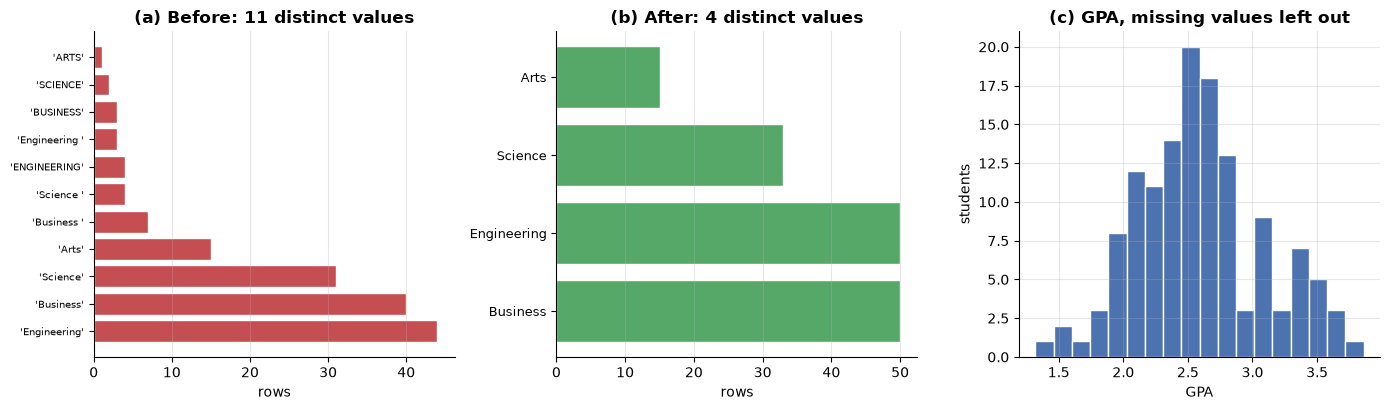

14 students are missing a GPA and are absent
from panel (c). Reporting that number alongside the chart is part of
the analysis, not a footnote.


In [110]:
# What cleaning changed, visually.
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))

before_counts = messy["faculty"].value_counts()
axes[0].barh(range(len(before_counts)), before_counts.to_numpy(),
             color=PALETTE[3], edgecolor="white")
axes[0].set_yticks(range(len(before_counts)),
                   [repr(v) for v in before_counts.index], fontsize=7)
axes[0].set_title(f"(a) Before: {messy['faculty'].nunique()} distinct values")
axes[0].set_xlabel("rows")
axes[0].grid(axis="y", alpha=0)

after_counts = cleaned["faculty"].value_counts()
axes[1].barh(range(len(after_counts)), after_counts.to_numpy(),
             color=PALETTE[2], edgecolor="white")
axes[1].set_yticks(range(len(after_counts)), list(after_counts.index), fontsize=9)
axes[1].set_title(f"(b) After: {cleaned['faculty'].nunique()} distinct values")
axes[1].set_xlabel("rows")
axes[1].grid(axis="y", alpha=0)

axes[2].hist(cleaned["gpa"].dropna(), bins=18, color=PALETTE[0], edgecolor="white")
axes[2].set_title("(c) GPA, missing values left out")
axes[2].set_xlabel("GPA")
axes[2].set_ylabel("students")

plt.tight_layout()
plt.show()

print(f"{int(cleaned['gpa'].isna().sum())} students are missing a GPA and are absent")
print("from panel (c). Reporting that number alongside the chart is part of")
print("the analysis, not a footnote.")

---

# Part 3 - Guided workshop (in class)

Four tasks. Each has a verification cell.

### Task 1 - Measure the damage

**Problem.** Before cleaning anything, quantify the problem. Compute three values:

1. `n_missing_total` - total missing values across the whole frame, as an `int`.
2. `pct_rows_affected` - the percentage of **rows** with at least one missing value, as a
   `float`.
3. `worst_column` - the name of the column with the most missing values, as a `str`.

**Hints**

- `df.isna()` gives a boolean frame the same shape as the original.
- `.any(axis=1)` collapses each row to "does this row have any?"
- `.idxmax()` on a Series returns the **label** of the largest value, not its position.

**Expected output.** Three values, followed by `Task 1 complete`.

In [134]:
# TODO 1a: Total missing values in the whole DataFrame
n_missing_total = int(messy.isnull().sum().sum())

# TODO 1b: Percentage of rows having at least one missing value
pct_rows_affected = float(messy.isnull().any(axis=1).mean() * 100)

# TODO 1c: Name of the column with the most missing values
worst_column = messy.isnull().sum().idxmax()

print(f"Total missing values      : {n_missing_total}")
print(f"Rows affected             : {pct_rows_affected}%")
print(f"Worst column              : {worst_column}")

Total missing values      : 144
Rows affected             : 77.56410256410257%
Worst column              : scholarship_usd


In [136]:
# Verification for Task 1.
want_total = int(messy.isna().sum().sum())
want_pct = float(messy.isna().any(axis=1).mean() * 100)
want_worst = messy.isna().sum().idxmax()

problems = []
if n_missing_total is None:
    problems.append("n_missing_total is still None")
elif int(n_missing_total) != want_total:
    problems.append(f"n_missing_total should be {want_total}, got {n_missing_total}")

if pct_rows_affected is None:
    problems.append("pct_rows_affected is still None")
elif not np.isclose(float(pct_rows_affected), want_pct):
    problems.append(f"pct_rows_affected should be about {want_pct:.1f}, "
                    f"got {pct_rows_affected} (percentage, not proportion)")

if worst_column is None:
    problems.append("worst_column is still None")
elif worst_column != want_worst:
    problems.append(f"worst_column should be {want_worst!r}, got {worst_column!r}")

if problems:
    print("Not complete:")
    for p in problems:
        print("  -", p)
else:
    print("Task 1 complete.")

Task 1 complete.


### Task 2 - Normalise the text

**Problem.** Build `faculty_clean`: the `faculty` column with surrounding whitespace removed
and consistent capitalisation, so that only the four real faculties remain.

**Hints**

- `.str.strip()` removes surrounding whitespace.
- `.str.title()` converts `"ENGINEERING"` to `"Engineering"`.
- Chain them: `series.str.strip().str.title()`.

**Expected output.** Four distinct values, followed by `Task 2 complete`.

In [115]:
# TODO 2: strip whitespace and normalise capitalisation.
faculty_clean = messy["faculty"].str.strip().str.title()  # replace this line

if faculty_clean is not None:
    print("Before:", messy["faculty"].nunique(), "distinct values")
    print("After :", faculty_clean.nunique(), "distinct values")
    print("\nValues:", sorted(faculty_clean.dropna().unique()))

Before: 11 distinct values
After : 4 distinct values

Values: ['Arts', 'Business', 'Engineering', 'Science']


In [116]:
# Verification for Task 2.
if faculty_clean is None:
    print("Not complete: `faculty_clean` is still None.")
elif not isinstance(faculty_clean, pd.Series):
    print(f"Expected a Series, got {type(faculty_clean).__name__}.")
else:
    distinct = set(faculty_clean.dropna().unique())
    expected = {"Engineering", "Business", "Science", "Arts"}
    if distinct != expected:
        print(f"Expected exactly {sorted(expected)}")
        print(f"Got              {sorted(distinct)}")
        if any(v != v.strip() for v in distinct):
            print("Some values still have surrounding whitespace — use .str.strip()")
        if any(v.isupper() for v in distinct):
            print("Some values are still upper case — use .str.title()")
    elif len(faculty_clean) != len(messy):
        print("The result must have one entry per row; do not drop anything.")
    else:
        print("Task 2 complete. Four distinct faculties.")

Task 2 complete. Four distinct faculties.


### Task 3 - Fill within groups

**Problem.** Fill the missing `attendance_pct` values with the **median attendance of that
student's faculty**, rather than the overall median. Store the result in `attendance_filled`.

Use the cleaned faculty column from Task 2.

**Hints**

- `df.groupby(key)[col].transform("median")` returns one value **per row**, aligned to the
  original index which is what `fillna` needs.
- `.agg("median")` would give one value per group and would not align.
- Build a temporary frame with the cleaned faculty, or pass the cleaned Series directly to
  `groupby`.

**Expected output.** No missing attendance values, with different faculties filled
differently. Followed by `Task 3 complete`.

In [117]:
# TODO 3a: compute the per-row faculty median of attendance_pct.
faculty_median_attendance = messy.assign(f=faculty_clean).groupby("f", observed=True)["attendance_pct"].transform("median")

# TODO 3b: use it to fill the missing values.
attendance_filled = messy["attendance_pct"].fillna(faculty_median_attendance)

if attendance_filled is not None:
    print(f"Missing before: {int(messy['attendance_pct'].isna().sum())}")
    print(f"Missing after : {int(attendance_filled.isna().sum())}")
    print("\nFaculty medians used:")
    print(messy.assign(f=faculty_clean).groupby("f", observed=True)["attendance_pct"]
          .median().round(2))

Missing before: 7
Missing after : 2

Faculty medians used:
f
Arts           77.10
Business       78.05
Engineering    76.10
Science        75.25
Name: attendance_pct, dtype: float64


In [118]:
# Verification for Task 3.
if attendance_filled is None or faculty_median_attendance is None:
    print("Not complete: fill in both TODO 3a and TODO 3b.")
else:
    reference_median = messy.assign(_f=faculty_clean).groupby("_f", observed=True)[
        "attendance_pct"].transform("median")
    reference = messy["attendance_pct"].fillna(reference_median)

    was_missing = messy["attendance_pct"].isna()

    if len(attendance_filled) != len(messy):
        print("The result must have one entry per row.")
    elif int(attendance_filled.isna().sum()) > 2:
        print(f"{int(attendance_filled.isna().sum())} values are still missing.")
        print("Every faculty has data, so only the rows with no faculty at all")
        print("should remain unfilled.")
    elif not np.allclose(attendance_filled[~was_missing].to_numpy(),
                         messy["attendance_pct"][~was_missing].to_numpy()):
        print("Values that were NOT missing must be left unchanged.")
    elif not np.allclose(attendance_filled.dropna().to_numpy(),
                         reference.dropna().to_numpy()):
        print("The filled values do not match the per-faculty medians.")
        print("Did you use transform('median') rather than agg or the overall median?")
    else:
        n_filled = int(was_missing.sum() - attendance_filled.isna().sum())
        print(f"Task 3 complete. {n_filled} values filled from their faculty median.")

Task 3 complete. 5 values filled from their faculty median.


### Task 4 - Assign without chaining

**Problem.** Add a `standing` column to `flagged` (a copy of the cleaned frame) with the value
`"probation"` for students whose GPA is below 2.0, and `"good"` for everyone else.

Students with a missing GPA must be labelled `"unknown"`.

Use `.loc`. Chained assignment will not work.

**Hints**

- Start by setting the whole column: `flagged["standing"] = "good"`.
- Then override with `.loc[mask, "standing"] = ...` twice.
- `.isna()` gives the mask for the unknown group. Apply it **last**, or a missing GPA will
  fail the `< 2.0` test and be labelled `"good"` first.

**Expected output.** Three categories with sensible counts, followed by `Task 4 complete`.

In [132]:
flagged = cleaned.copy()

# TODO 4: add the `standing` column using .loc, in three steps.
flagged.loc[ (flagged["gpa"] >= 2.0), "standing"] = "good"
flagged.loc[flagged["gpa"] < 2.0, "standing"] = "probation"
flagged.loc[flagged["gpa"].isna(), "standing"] = "unknown"


print(flagged["standing"].value_counts() if "standing" in flagged.columns
      else "column not created yet")

standing
good         121
unknown       14
probation     13
Name: count, dtype: int64


In [133]:
# Verification for Task 4.
if "standing" not in flagged.columns:
    print("Not complete: no `standing` column was created.")
else:
    gpa = flagged["gpa"]
    expected = pd.Series("good", index=flagged.index)
    expected[gpa < 2.0] = "probation"
    expected[gpa.isna()] = "unknown"

    if not flagged["standing"].equals(expected):
        mismatch = (flagged["standing"] != expected).sum()
        print(f"{mismatch} rows are labelled incorrectly.")
        wrong_unknown = ((gpa.isna()) & (flagged["standing"] != "unknown")).sum()
        if wrong_unknown:
            print(f"  {wrong_unknown} rows with a missing GPA are not 'unknown'.")
            print("  Apply the isna() mask last, or missing GPAs get labelled first.")
    else:
        print("Task 4 complete.")
        print(flagged["standing"].value_counts().to_string())

Task 4 complete.
standing
good         121
unknown       14
probation     13


---

# Part 4 - Homework

Run **Restart Kernel and Run All Cells** before submitting, then push to your
`puc-data-analysis` repository.

## Problem 1 - An auditable cleaning function

A cleaning step that leaves no record is impossible to review. This function cleans and
reports what it did.

**Problem.** Write `clean_and_report(df)`.

**Requirements.** Return a **tuple** `(clean_df, report)` where `report` is a dictionary with
exactly these keys:

| Key | Type | Value |
|---|---|---|
| `rows_in` | `int` | Rows in the input |
| `rows_out` | `int` | Rows in the result |
| `duplicates_removed` | `int` | Rows removed as duplicate `student_id` |
| `empty_rows_removed` | `int` | Rows removed for being empty apart from `student_id` |
| `values_filled` | `int` | Count of `scholarship_usd` blanks filled with 0 |
| `unparseable_credits` | `int` | `credits` values that could not be converted |

**The cleaning steps, in this order:**

1. Strip whitespace and title-case `faculty`.
2. Drop rows where **all** of `faculty`, `credits`, `gpa`, `attendance_pct` and
   `scholarship_usd` are missing.
3. Drop duplicate `student_id`, keeping the first.
4. Convert `credits` with `pd.to_numeric(errors="coerce")`, then to `"Int64"`.
5. Fill missing `scholarship_usd` with `0.0`.
6. Leave `gpa` missing. Do **not** fill it.
7. Reset the index with `drop=True`.

Do not modify the input frame.

**Hints**

- The order matters: normalise text *before* deduplicating, or `"Arts"` and `"ARTS"` will not
  be recognised as the same.
- Count `unparseable_credits` as values that are non-missing before conversion and missing
  after. Count them **before** filling anything.
- `df.copy()` on the first line, every time.

In [160]:

KEY_COLUMNS = ["faculty", "credits", "gpa", "attendance_pct", "scholarship_usd"]


def clean_and_report(df: pd.DataFrame) -> tuple:
    """Clean an enrolment frame and report what each step did."""

    # Step 1: Make a copy of the input
    clean_df = df.copy()

    # Step 2: Count input rows
    rows_in = len(clean_df)

    # Step 3: Normalize faculty names
    clean_df["faculty"] = (
        clean_df["faculty"]
        .str.strip()
        .str.title()
    )

    # Step 4: Count and remove empty rows
    empty_mask = clean_df[KEY_COLUMNS].isna().all(axis=1)
    empty_rows_removed = int(empty_mask.sum())

    clean_df = clean_df.loc[~empty_mask].copy()

    # Step 5: Count and remove duplicate student IDs
    duplicates_removed = int(
        clean_df["student_id"].duplicated().sum()
    )

    clean_df = clean_df.drop_duplicates(
        subset="student_id",
        keep="first"
    )

    # Step 6: Count unparseable credits before conversion
    numeric_credits = pd.to_numeric(
        clean_df["credits"],
        errors="coerce"
    )

    unparseable_credits = int(
        (clean_df["credits"].notna() & numeric_credits.isna()).sum()
    )

    # Convert credits to nullable integer
    clean_df["credits"] = numeric_credits.astype("Int64")

    # Step 7: Fill missing scholarship values
    values_filled = int(clean_df["scholarship_usd"].isna().sum())

    clean_df["scholarship_usd"] = (
        clean_df["scholarship_usd"].fillna(0.0)
    )

    # Leave GPA missing and reset index
    clean_df = clean_df.reset_index(drop=True)

    # Create report
    report = {
        "rows_in": int(rows_in),
        "rows_out": int(len(clean_df)),
        "duplicates_removed": int(duplicates_removed),
        "empty_rows_removed": int(empty_rows_removed),
        "values_filled": int(values_filled),
        "unparseable_credits": int(unparseable_credits)
    }

    return clean_df, report


result, report = clean_and_report(messy)

print("Report:")
for key, value in report.items():
    print(f"  {key:<22} {value}")

print(f"\nResult: {result.shape[0]} rows x {result.shape[1]} columns")
print(result.dtypes)


Report:
  rows_in                156
  rows_out               148
  duplicates_removed     6
  empty_rows_removed     2
  values_filled          107
  unparseable_credits    1

Result: 148 rows x 6 columns
student_id             str
faculty                str
credits              Int64
gpa                float64
attendance_pct     float64
scholarship_usd    float64
dtype: object


In [161]:
# Problem 1 — validation. All assertions must pass.
original_shape = messy.shape
result, report = clean_and_report(messy)

# --- return shape ---
assert isinstance(result, pd.DataFrame), "The first return value must be a DataFrame"
assert isinstance(report, dict), "The second return value must be a dict"

expected_keys = {"rows_in", "rows_out", "duplicates_removed", "empty_rows_removed",
                 "values_filled", "unparseable_credits"}
assert set(report.keys()) == expected_keys, (
    f"Report keys must be exactly {sorted(expected_keys)}; got {sorted(report.keys())}"
)
for key, value in report.items():
    assert isinstance(value, int), f"{key} must be a Python int, got {type(value).__name__}"

# --- the input is untouched ---
assert messy.shape == original_shape, "clean_and_report must not modify its input"
assert messy["faculty"].nunique() > 4, (
    "The input's faculty column must still be messy — work on a copy"
)

# --- counts are consistent with each other ---
assert report["rows_in"] == len(messy)
assert report["rows_out"] == len(result)
assert report["rows_in"] - report["rows_out"] == (
    report["duplicates_removed"] + report["empty_rows_removed"]
), "Rows lost must equal duplicates removed plus empty rows removed"

# --- the known defects were found ---
assert report["empty_rows_removed"] == 2, (
    f"The generator inserts 2 empty rows; got {report['empty_rows_removed']}"
)
assert report["duplicates_removed"] == 6, (
    f"The generator appends 6 duplicate rows; got {report['duplicates_removed']}"
)
assert report["unparseable_credits"] == 1, (
    f"Exactly one credits value reads 'not recorded'; got {report['unparseable_credits']}"
)
assert report["values_filled"] > 0, "Some scholarship_usd blanks should have been filled"

# --- text was normalised ---
assert set(result["faculty"].dropna().unique()) == {
    "Engineering", "Business", "Science", "Arts"
}, f"faculty should hold exactly the four names; got {sorted(set(result['faculty'].dropna().unique()))}"

# --- types ---
assert str(result["credits"].dtype) == "Int64", (
    f"credits must be the nullable Int64 type; got {result['credits'].dtype}"
)

# --- filling and not filling ---
assert result["scholarship_usd"].isna().sum() == 0, "scholarship_usd must be fully filled"
assert result["gpa"].isna().sum() > 0, (
    "gpa must be left missing — filling it would invent data"
)

# --- no duplicate identifiers remain ---
assert not result["student_id"].duplicated().any(), "Duplicate student_id values remain"

# --- the index was reset ---
assert isinstance(result.index, pd.RangeIndex), "Reset the index with drop=True"
assert result.index[0] == 0

# --- running it twice changes nothing further (idempotent) ---
again, report2 = clean_and_report(result)
assert report2["duplicates_removed"] == 0, "Cleaning an already-clean frame removes nothing"
assert report2["empty_rows_removed"] == 0
assert len(again) == len(result)

print("Problem 1: all assertions passed.")

Problem 1: all assertions passed.


---

## Problem 2 - Group-wise filling with a fallback

Filling from a group median is better than filling from the overall median until a group has
no data at all, and the group median is itself `NaN`. A function that ignores that case
silently leaves values unfilled.

**Problem.** Write `fill_by_group(df, value_col, group_col)`.

**Requirements.** Return a **new** `Series`, aligned to `df.index`, in which every missing
value of `value_col` has been filled by:

1. the **median of its group**, if that group has at least one non-missing value; otherwise
2. the **median of the whole column**, as a fallback.

Values that were not missing must be returned unchanged.

**Requirements on behaviour**

| Situation | Behaviour |
|---|---|
| Group has data | Fill with the group median |
| Group has no data at all | Fill with the overall median |
| Group label itself is missing | Fill with the overall median |
| The whole column is missing | Return it unchanged; there is nothing to fill from |
| `value_col` or `group_col` absent | Raise `KeyError` |

Do not modify the input frame.

**Hints**

- `df.groupby(group_col)[value_col].transform("median")` gives the per-row group median, and
  is `NaN` for a group with no data and for rows whose group label is missing.
- Fill in two passes: first with the group median, then with the overall median. A second
  `fillna` handles everything the first one missed.
- Guard the empty case: if the column is entirely missing, the overall median is `NaN` and
  filling with it changes nothing which is the required behaviour, so no special case is
  needed. Check that it does not raise.
- Use `observed=True` in `groupby` if `group_col` is categorical, to avoid a warning about
  unused categories.

In [165]:
# Problem 2 — starter code.

def fill_by_group(df: pd.DataFrame, value_col: str, group_col: str) -> pd.Series:
    """Fill missing values from the group median, falling back to the overall median.

    Parameters
    ----------
    df : pandas.DataFrame
        The frame to read from. Not modified.
    value_col : str
        The numeric column to fill.
    group_col : str
        The column to group by.

    Returns
    -------
    pandas.Series
        A new Series aligned to df.index.

    Raises
    ------
    KeyError
        If either column is absent.
    """
    # TODO: implement as described above.
    if value_col not in df.columns:
        raise KeyError(f"Column '{value_col}' not found in DataFrame.")
    if group_col not in df.columns:
        raise KeyError(f"Column '{group_col}' not found in DataFrame.")
    group_median = df.groupby(group_col, observed=True)[value_col].transform("median")
    overall_median = df[value_col].median()
    filled_series = df[value_col].fillna(group_median).fillna(overall_median)
    return filled_series   
    


work = messy.assign(faculty=messy["faculty"].str.strip().str.title())
filled_gpa = fill_by_group(work, "gpa", "faculty")

print(f"Missing before: {int(work['gpa'].isna().sum())}")
print(f"Missing after : {int(filled_gpa.isna().sum())}")
print("\nMedian GPA by faculty:")
print(work.groupby("faculty", observed=True)["gpa"].median().round(3))

Missing before: 18
Missing after : 0

Median GPA by faculty:
faculty
Arts           2.480
Business       2.565
Engineering    2.520
Science        2.545
Name: gpa, dtype: float64


In [166]:
# Problem 2 — validation. All assertions must pass.

sample = pd.DataFrame({
    "team":  ["A", "A", "A", "B", "B", "C", "C", None],
    "score": [10.0, 20.0, np.nan, 5.0, np.nan, np.nan, np.nan, np.nan],
})
# Group A median = 15.0; Group B median = 5.0; Group C has NO data;
# the last row has no group label. Overall median of [10, 20, 5] = 10.0

out = fill_by_group(sample, "score", "team")

assert isinstance(out, pd.Series), "fill_by_group must return a Series"
assert out.index.equals(sample.index), "The result must be aligned to df.index"
assert len(out) == len(sample)

# --- values that were present are unchanged ---
assert np.isclose(out.iloc[0], 10.0)
assert np.isclose(out.iloc[1], 20.0)
assert np.isclose(out.iloc[3], 5.0)

# --- group A filled from its own median ---
assert np.isclose(out.iloc[2], 15.0), (
    f"Group A has values 10 and 20, so its median is 15.0; got {out.iloc[2]}"
)

# --- group B filled from its own median ---
assert np.isclose(out.iloc[4], 5.0), (
    f"Group B has one value, 5.0, so its median is 5.0; got {out.iloc[4]}"
)

# --- group C has no data at all: fall back to the overall median ---
overall = sample["score"].median()
assert np.isclose(overall, 10.0), "Sanity check on the test data"
assert np.isclose(out.iloc[5], overall), (
    f"Group C has no values, so the overall median {overall} must be used; got {out.iloc[5]}"
)
assert np.isclose(out.iloc[6], overall)

# --- a missing group label also falls back ---
assert np.isclose(out.iloc[7], overall), (
    f"A row with no group label must use the overall median; got {out.iloc[7]}"
)

# --- nothing is left missing when any data exists ---
assert out.isna().sum() == 0, "With a usable fallback, no value should remain missing"

# --- the input is untouched ---
assert sample["score"].isna().sum() == 5, "fill_by_group must not modify its input"

# --- a column that is entirely missing is returned unchanged, without raising ---
all_missing = pd.DataFrame({"g": ["A", "B"], "v": [np.nan, np.nan]})
untouched = fill_by_group(all_missing, "v", "g")
assert untouched.isna().all(), "With nothing to fill from, the values stay missing"

# --- a column with no missing values is returned unchanged ---
complete = pd.DataFrame({"g": ["A", "A", "B"], "v": [1.0, 2.0, 3.0]})
same = fill_by_group(complete, "v", "g")
assert np.allclose(same.to_numpy(), [1.0, 2.0, 3.0])

# --- a bad column name raises KeyError ---
for bad_value, bad_group in [("nope", "team"), ("score", "nope")]:
    try:
        fill_by_group(sample, bad_value, bad_group)
    except KeyError:
        pass
    else:
        raise AssertionError(
            f"fill_by_group(df, {bad_value!r}, {bad_group!r}) must raise KeyError"
        )

# --- it works on the notebook's own data ---
real = fill_by_group(work, "gpa", "faculty")
assert real.isna().sum() == 0, "Every faculty has GPA data, so nothing should remain missing"
assert np.allclose(real[~work["gpa"].isna()].to_numpy(),
                   work["gpa"].dropna().to_numpy()), "Present values must be unchanged"

print("Problem 2: all assertions passed.")

Problem 2: all assertions passed.


---

## Submission checklist

- [ ] All four workshop tasks print their `complete` message.
- [ ] Problem 1 prints `all assertions passed`.
- [ ] Problem 2 prints `all assertions passed`.
- [ ] **Restart Kernel and Run All Cells** completes with no errors.
- [ ] Committed and pushed to your `puc-data-analysis` repository.

## Looking ahead to Week 6

Week 6 is manipulation: filtering, sorting, grouping, aggregating, and joining tables
together. The `groupby(...).transform(...)` you used today is a preview of it.

Before the session, read McKinney §8.1–8.2 and §10.1–10.2.

---

## References

McKinney, W. (2022). *Python for Data Analysis* (3rd ed.). O'Reilly Media. §7.1–7.4.

Pfaffelhuber, P. *Python for Data Analysis* (course notes). §7.7.
Available at `https://pfaffelh.github.io/python_for_data/`.